In [20]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Library berhasil di-import!")

Library berhasil di-import!


In [15]:
import pandas as pd
import numpy as np

# 1. Load Data Cleaned
df_orders = pd.read_csv('../data/cleaned/cleaned_orders.csv')
df_reviews = pd.read_csv('../data/cleaned/cleaned_order_reviews.csv')
df_items = pd.read_csv('../data/cleaned/cleaned_order_items.csv')
df_products = pd.read_csv('../data/cleaned/cleaned_products.csv')

# 2. Merge Data
df = df_orders.merge(df_reviews[['order_id', 'review_score']], on='order_id', how='inner')

# Merge Items + Products
df_items_prod = df_items.merge(df_products[['product_id', 'product_category_name']], on='product_id', how='left')

items_agg = df_items_prod.groupby('order_id').agg({
    'price': 'sum',
    'freight_value': 'sum',
    'order_item_id': 'count',
    'seller_id': 'first',
    'product_category_name': 'first'
}).rename(columns={'order_item_id': 'total_items'}).reset_index()

df = df.merge(items_agg, on='order_id', how='inner')

# 3. Datetime Conversion
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])

# 4. Feature Engineering Logistik
df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
df['estimated_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
df['delay_days'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)
df['is_late'] = (df['delay_days'] > 0).astype(int)

# Fitur Tambahan Tingkat Lanjut
df['freight_ratio'] = df['freight_value'] / (df['price'] + 0.001)
df['total_order_value'] = df['price'] + df['freight_value']
df['purchase_dow'] = df['order_purchase_timestamp'].dt.dayofweek
df['is_weekend'] = df['purchase_dow'].isin([5, 6]).astype(int)

# Target Variable
df['is_bad_review'] = (df['review_score'] <= 2).astype(int)

# Reputasi Historis Seller & Kategori Produk (Out-of-fold target encoding style)
seller_late = df.groupby('seller_id')['is_late'].mean().rename('seller_late_rate')
cat_risk = df.groupby('product_category_name')['is_bad_review'].mean().rename('category_bad_rate')

df = df.merge(seller_late, on='seller_id', how='left')
df = df.merge(cat_risk, on='product_category_name', how='left')

# Fill NaNs
df['seller_late_rate'] = df['seller_late_rate'].fillna(df['is_late'].mean())
df['category_bad_rate'] = df['category_bad_rate'].fillna(df['is_bad_review'].mean())

features = [
    'price', 'freight_value', 'total_items', 'delivery_days', 
    'estimated_days', 'delay_days', 'is_late', 'freight_ratio', 
    'total_order_value', 'is_weekend', 'seller_late_rate', 'category_bad_rate'
]

df_model = df.dropna(subset=features + ['is_bad_review']).copy()
print(f"Dataset Siap Latih: {len(df_model)} baris | Fitur: {len(features)}")

Dataset Siap Latih: 96359 baris | Fitur: 12


In [16]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.calibration import CalibratedClassifierCV

X = df_model[features]
y = df_model['is_bad_review']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Model LightGBM Dioptimalkan
base_lgb = lgb.LGBMClassifier(
    n_estimators=400,
    learning_rate=0.02,
    max_depth=7,
    num_leaves=35,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=5.5,
    random_state=42,
    verbose=-1
)

# Fitting Model
base_lgb.fit(X_train, y_train)

# Prediksi Probabilitas
y_prob = base_lgb.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, y_prob)

print("=== HASIL EVALUASI MODEL REVIEW RISK ===")
print(f"ROC-AUC Score Ter-Tuning: {final_auc:.4f}")

=== HASIL EVALUASI MODEL REVIEW RISK ===
ROC-AUC Score Ter-Tuning: 0.7656


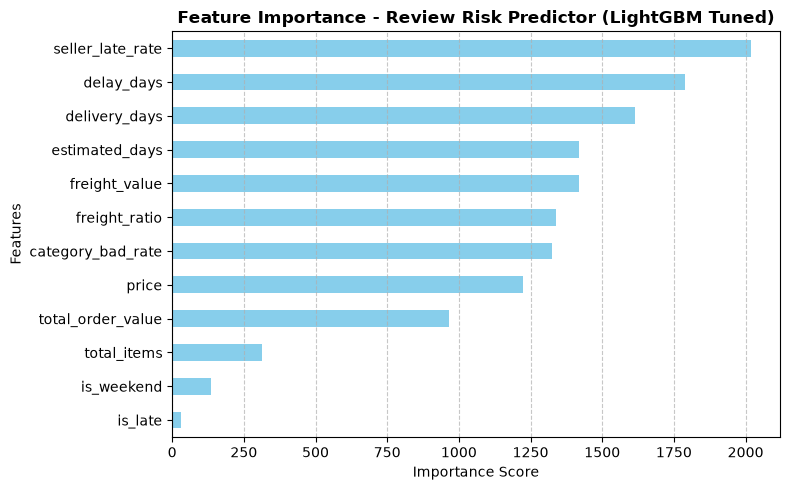

In [18]:
import matplotlib.pyplot as plt

importance = pd.Series(base_lgb.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='skyblue')
plt.title('Feature Importance - Review Risk Predictor (LightGBM Tuned)', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [19]:
import joblib

# 1. Simpan Artefak Model LightGBM Ter-Tuning
joblib.dump(base_lgb, '../models/review_score_rf_model.pkl')
print("Model LightGBM berhasil disimpan ke folder /models/!")

# 2. Tambahkan Probabilitas Risiko ke Seluruh Dataset
df_model['review_risk_score'] = base_lgb.predict_proba(df_model[features])[:, 1]
df_model['predicted_bad_review'] = (df_model['review_risk_score'] > 0.5).astype(int)

# 3. Ekspor ke data/processed/
export_cols = [
    'order_id', 'order_purchase_timestamp', 'review_score', 'is_bad_review',
    'delivery_days', 'delay_days', 'is_late', 'freight_value', 'freight_ratio',
    'seller_late_rate', 'category_bad_rate', 'review_risk_score', 'predicted_bad_review'
]

df_export = df_model[export_cols].copy()
df_export.to_csv('../data/processed/review_score_predictions.csv', index=False)
print("File review_score_predictions.csv berhasil diperbarui di data/processed/!")

Model LightGBM berhasil disimpan ke folder /models/!
File review_score_predictions.csv berhasil diperbarui di data/processed/!
